In [ ]:
from pathlib import Path

import h5py
from scipy.io import loadmat
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from Experimental_Analysis import Experimental_Analysis
from Simulation_Import_Analysis import Simulation_Import_Analysis
from scipy.optimize import curve_fit


In [2]:
# Change these values, then rerun this cell and the plotting cells below.
FONT_FAMILY = "Arial"  # Choose an installed font, e.g. "Arial" or "Times New Roman".
FONT_SIZE = 14  # points

plt.rcParams.update({
    "font.family": FONT_FAMILY,
    "savefig.dpi": 600,  # High resolution for exported images.
    "font.size": FONT_SIZE,
    "axes.titlesize": FONT_SIZE,
    "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "legend.fontsize": FONT_SIZE,
    "legend.title_fontsize": FONT_SIZE,
    "figure.titlesize": FONT_SIZE,
})

## µ-optics region: $\lambda/16$; else: $\lambda/14$ ##

In [3]:
LUMERICAL_DATA_DIR = Path(
    "/Users/yiyangzhi/Library/CloudStorage/GoogleDrive-yiyang_zhi3@berkeley.edu/"
    "My Drive/Ming Wu Integrated Photonics Group/Simulations/Lumerical/"
    "Integrated_Trapped_Ions_Library/focus_investigate/optical_lambda16_else_lambda14")

In [ ]:
height_um = np.arange(116, 137)  # 116–136 µm, inclusive

simulations = [
    Simulation_Import_Analysis(
        f"XY_cut_{h}.mat",
        data_dir=LUMERICAL_DATA_DIR,
    ).fit_gaussian_slices()
    for h in height_um
]

# Fitted 1/e² radii, aligned with height_um.
axial_waist_um = np.array([sim.axial_waist_um for sim in simulations])
radial_waist_um = np.array([sim.radial_waist_um for sim in simulations])

# Optional access by height, e.g. sim_by_height[126].
sim_by_height = dict(zip(height_um, simulations))

# max_intensity[i] corresponds to height_um[i].
max_intensity = np.array([sim.P.max() for sim in simulations])


116 µm: 0.00886234
117 µm: 0.0095797
118 µm: 0.0103167
119 µm: 0.0110504
120 µm: 0.0117567
121 µm: 0.0124121
122 µm: 0.0129946
123 µm: 0.0134865
124 µm: 0.0138717
125 µm: 0.0141417
126 µm: 0.0142897
127 µm: 0.014316
128 µm: 0.0142194
129 µm: 0.0140037
130 µm: 0.0136781
131 µm: 0.0132525
132 µm: 0.0127425
133 µm: 0.012166
134 µm: 0.0115428
135 µm: 0.0108902
136 µm: 0.010224


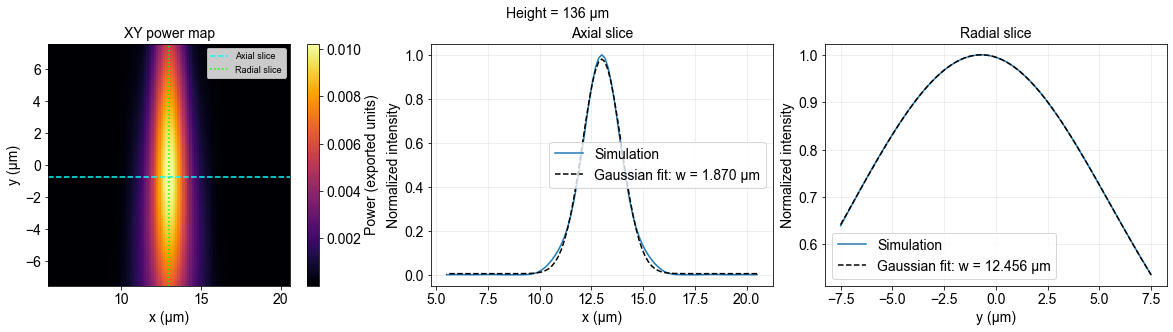

In [16]:
plot_height_um = 136  # Change this height and rerun.

# Select the nearest available height.
idx = np.argmin(np.abs(height_um - plot_height_um))
selected_height = height_um[idx]
sim = simulations[idx]

# Reset slices through the intensity maximum, then fit them.
sim.get_axial_slice()
sim.get_radial_slice()
sim.fit_gaussian_slices()

fig, axes = plt.subplots(
    1, 3, figsize=(17, 4.5), constrained_layout=True
)

# XY power map: match the coordinate convention used by the class.
im = axes[0].pcolormesh(
    sim.x_um,
    sim.y_um,
    np.fliplr(sim.P),
    shading="auto",
    cmap="inferno",
)
fig.colorbar(im, ax=axes[0], label="Power (exported units)")
axes[0].axhline(sim.axial_y_um, color="cyan", ls="--", label="Axial slice")
axes[0].axvline(sim.radial_x_um, color="lime", ls=":", label="Radial slice")
axes[0].set(
    xlabel="x (µm)",
    ylabel="y (µm)",
    title="XY power map",
    aspect="equal",
)
axes[0].legend(fontsize=9)

# Axial and radial profiles with Gaussian fits.
profiles = [
    (axes[1], sim.x_um, sim.axial_slice, sim.axial_fit,
     sim.axial_waist_um, "Axial", "x"),
    (axes[2], sim.y_um, sim.radial_slice, sim.radial_fit,
     sim.radial_waist_um, "Radial", "y"),
]

for ax, position, intensity, fit, waist, name, coordinate in profiles:
    ax.plot(position, intensity, color="C0", label="Simulation")
    ax.plot(
        position, fit, "k--",
        label=f"Gaussian fit: w = {waist:.3f} µm",
    )
    ax.set(
        xlabel=f"{coordinate} (µm)",
        ylabel="Normalized intensity",
        title=f"{name} slice",
    )
    ax.legend()
    ax.grid(alpha=0.25)

fig.suptitle(f"Height = {selected_height:g} µm")
plt.show()

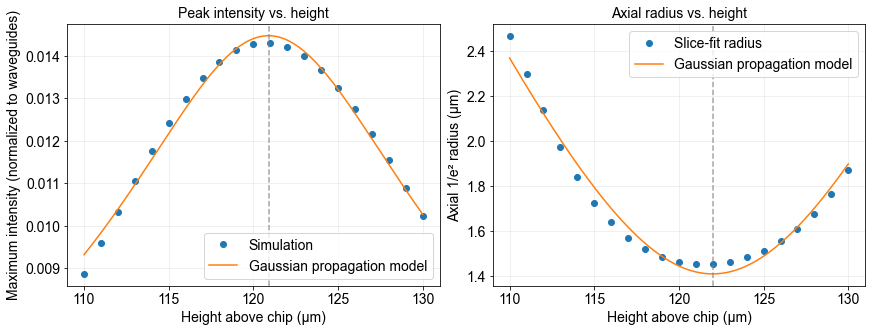

Radius fit:    focus height = 121.993 µm
               minimum radius = 1.410 µm; hR = 8.872 µm
Intensity fit: peak height = 120.897 µm
               peak intensity = 0.0144806
               hR = 9.155 µm


In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# 0.5: approximately constant radial radius (appropriate for these files).
# 1.0: circular Gaussian with both radii expanding together.
intensity_exponent = 0.5

h = np.asarray(height_um, dtype=float)
max_intensity = np.array([sim.P.max() for sim in simulations])
axial_waist_um = np.array([sim.axial_waist_um for sim in simulations])

def waist_model(h, w0, h0, hR):
    return w0 * np.sqrt(1 + ((h - h0) / hR)**2)

def intensity_model(h, I0, h0, hR):
    return I0 / (1 + ((h - h0) / hR)**2)**intensity_exponent

# Fit the axial 1/e² radius.
waist_params, waist_cov = curve_fit(
    waist_model,
    h,
    axial_waist_um,
    p0=[
        axial_waist_um.min(),
        h[np.argmin(axial_waist_um)],
        np.ptp(h) / 2,
    ],
    bounds=([1e-9, -np.inf, 1e-9], [np.inf, np.inf, np.inf]),
    maxfev=20000,
)

# Scale intensity during fitting for numerical stability.
intensity_scale = max_intensity.max()
intensity_params, intensity_cov = curve_fit(
    intensity_model,
    h,
    max_intensity / intensity_scale,
    p0=[1.0, h[np.argmax(max_intensity)], waist_params[2]],
    bounds=([0, -np.inf, 1e-9], [np.inf, np.inf, np.inf]),
    maxfev=20000,
)

h_plot = np.linspace(h.min(), h.max(), 500)

fig, axes = plt.subplots(
    1, 2, figsize=(12, 4.5), constrained_layout=True
)

# First subplot: maximum raw intensity.
axes[0].plot(h-6, max_intensity, "o", label="Simulation")
axes[0].plot(
    h_plot-6,
    intensity_scale * intensity_model(h_plot, *intensity_params),
    "-", label="Gaussian propagation model",
)
axes[0].axvline(intensity_params[1]-6, color="gray", ls="--", alpha=0.7)
axes[0].set(
    xlabel="Height above chip (µm)",
    ylabel="Maximum intensity (normalized to waveguides)",
    title="Peak intensity vs. height",
)

# Second subplot: axial 1/e² radius.
axes[1].plot(h-6, axial_waist_um, "o", label="Slice-fit radius")
axes[1].plot(
    h_plot-6, waist_model(h_plot, *waist_params),
    "-", label="Gaussian propagation model",
)
axes[1].axvline(waist_params[1]-6, color="gray", ls="--", alpha=0.7)
axes[1].set(
    xlabel="Height above chip (µm)",
    ylabel="Axial 1/e² radius (µm)",
    title="Axial radius vs. height",
)

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)

plt.show()

w0, h0, hR = waist_params
I0_scaled, hI, hRI = intensity_params

print(f"Radius fit:    focus height = {h0-6:.3f} µm")
print(f"               minimum radius = {w0:.3f} µm; hR = {hR:.3f} µm")
print(f"Intensity fit: peak height = {hI-6:.3f} µm")
print(f"               peak intensity = {I0_scaled * intensity_scale:.6g}")
print(f"               hR = {hRI:.3f} µm")

## Everywhere: $\lambda/10$ ##

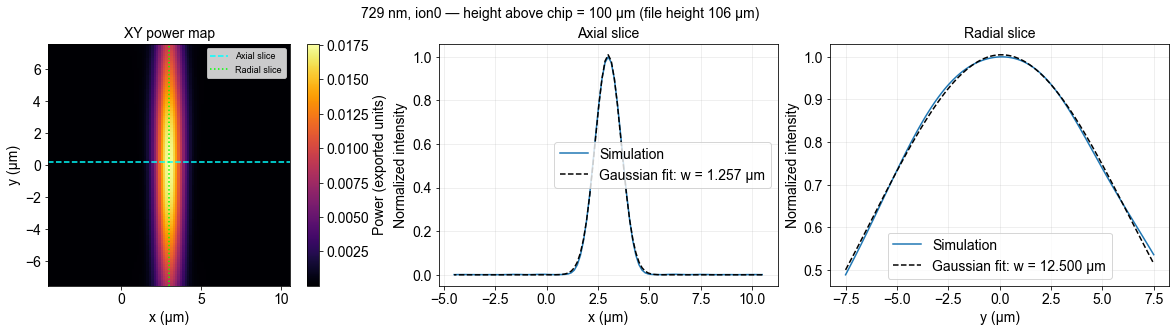

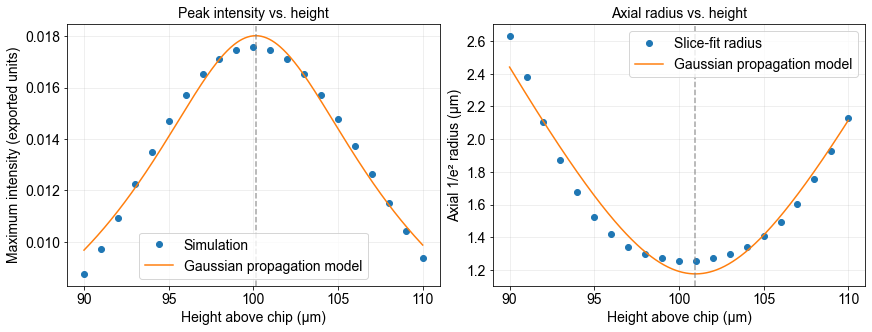

Loaded 21 simulations.
Radius fit:    focus height above chip = 100.978 µm
               minimum radius = 1.176 µm
               hR = 6.036 µm
Intensity fit: peak height above chip = 100.144 µm
               peak intensity = 0.0180192
               hR = 6.457 µm


In [23]:
# ===================== Settings =====================
plot_height_um = 106  # File height; 100 µm above chip.
CHIP_SURFACE_HEIGHT_UM = 6.0
FONT_FAMILY = "Arial"
FONT_SIZE = 14

# 0.5 assumes approximately constant radial width.
# 1.0 assumes a circular Gaussian expanding in both directions.
intensity_exponent = 0.5

plt.rcParams.update({
    "font.family": FONT_FAMILY,
    "font.size": FONT_SIZE,
    "savefig.dpi": 600,
})

LUMERICAL_DATA_DIR = Path(
    "/Users/yiyangzhi/Library/CloudStorage/"
    "GoogleDrive-yiyang_zhi3@berkeley.edu/"
    "My Drive/Ming Wu Integrated Photonics Group/Simulations/Lumerical/"
    "Integrated_Trapped_Ions_Library/Ca_100um_RMQA_FINAL/729_nm/ion0"
)

# ===================== Load and fit slices =====================
height_um = np.arange(96, 117)
height_above_chip_um = height_um - CHIP_SURFACE_HEIGHT_UM

simulations = [
    Simulation_Import_Analysis(
        f"XY_cut_{h}.mat",
        data_dir=LUMERICAL_DATA_DIR,
    ).fit_gaussian_slices()
    for h in height_um
]

sim_by_height = dict(zip(height_um, simulations))

max_intensity = np.array([sim.P.max() for sim in simulations])
axial_waist_um = np.array([sim.axial_waist_um for sim in simulations])
radial_waist_um = np.array([sim.radial_waist_um for sim in simulations])

# ===================== Selected-height visualization =====================
idx = np.argmin(np.abs(height_um - plot_height_um))
selected_height = height_um[idx]
sim = simulations[idx]

sim.get_axial_slice()
sim.get_radial_slice()
sim.fit_gaussian_slices()

fig, axes = plt.subplots(
    1, 3, figsize=(17, 4.5), constrained_layout=True
)

# Mirror P to match the class's x-coordinate convention.
im = axes[0].pcolormesh(
    sim.x_um, sim.y_um, np.fliplr(sim.P),
    shading="auto", cmap="inferno",
)
fig.colorbar(im, ax=axes[0], label="Power (exported units)")
axes[0].axhline(
    sim.axial_y_um, color="cyan", ls="--", label="Axial slice"
)
axes[0].axvline(
    sim.radial_x_um, color="lime", ls=":", label="Radial slice"
)
axes[0].set(
    xlabel="x (µm)",
    ylabel="y (µm)",
    title="XY power map",
    aspect="equal",
)
axes[0].legend(fontsize=9)

profiles = [
    (
        axes[1], sim.x_um, sim.axial_slice, sim.axial_fit,
        sim.axial_waist_um, "Axial", "x",
    ),
    (
        axes[2], sim.y_um, sim.radial_slice, sim.radial_fit,
        sim.radial_waist_um, "Radial", "y",
    ),
]

for ax, position, intensity, fit, waist, name, coordinate in profiles:
    ax.plot(position, intensity, color="C0", label="Simulation")
    ax.plot(
        position, fit, "k--",
        label=f"Gaussian fit: w = {waist:.3f} µm",
    )
    ax.set(
        xlabel=f"{coordinate} (µm)",
        ylabel="Normalized intensity",
        title=f"{name} slice",
    )
    ax.legend()
    ax.grid(alpha=0.25)

fig.suptitle(
    f"729 nm, ion0 — height above chip = "
    f"{selected_height - CHIP_SURFACE_HEIGHT_UM:g} µm "
    f"(file height {selected_height:g} µm)"
)
plt.show()

# ===================== Gaussian propagation fits =====================
h = np.asarray(height_above_chip_um, dtype=float)

def waist_model(h, w0, h0, hR):
    return w0 * np.sqrt(1 + ((h - h0) / hR)**2)

def intensity_model(h, I0, h0, hR):
    return I0 / (1 + ((h - h0) / hR)**2)**intensity_exponent

waist_params, waist_cov = curve_fit(
    waist_model,
    h,
    axial_waist_um,
    p0=[
        axial_waist_um.min(),
        h[np.argmin(axial_waist_um)],
        np.ptp(h) / 2,
    ],
    bounds=([1e-9, -np.inf, 1e-9], [np.inf, np.inf, np.inf]),
    maxfev=20000,
)

# Scale intensity during fitting for numerical stability.
intensity_scale = max_intensity.max()

intensity_params, intensity_cov = curve_fit(
    intensity_model,
    h,
    max_intensity / intensity_scale,
    p0=[1.0, h[np.argmax(max_intensity)], waist_params[2]],
    bounds=([0, -np.inf, 1e-9], [np.inf, np.inf, np.inf]),
    maxfev=20000,
)

# ===================== Height-dependent plots =====================
h_plot = np.linspace(h.min(), h.max(), 500)

fig, axes = plt.subplots(
    1, 2, figsize=(12, 4.5), constrained_layout=True
)

axes[0].plot(h, max_intensity, "o", label="Simulation")
axes[0].plot(
    h_plot,
    intensity_scale * intensity_model(h_plot, *intensity_params),
    "-",
    label="Gaussian propagation model",
)
axes[0].axvline(
    intensity_params[1], color="gray", ls="--", alpha=0.7
)
axes[0].set(
    xlabel="Height above chip (µm)",
    ylabel="Maximum intensity (exported units)",
    title="Peak intensity vs. height",
)

axes[1].plot(h, axial_waist_um, "o", label="Slice-fit radius")
axes[1].plot(
    h_plot,
    waist_model(h_plot, *waist_params),
    "-",
    label="Gaussian propagation model",
)
axes[1].axvline(
    waist_params[1], color="gray", ls="--", alpha=0.7
)
axes[1].set(
    xlabel="Height above chip (µm)",
    ylabel="Axial 1/e² radius (µm)",
    title="Axial radius vs. height",
)

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)

plt.show()

# ===================== Fit results =====================
w0, h0, hR = waist_params
I0_scaled, hI, hRI = intensity_params

print(f"Loaded {len(simulations)} simulations.")
print(f"Radius fit:    focus height above chip = {h0:.3f} µm")
print(f"               minimum radius = {w0:.3f} µm")
print(f"               hR = {hR:.3f} µm")
print(f"Intensity fit: peak height above chip = {hI:.3f} µm")
print(f"               peak intensity = {I0_scaled * intensity_scale:.6g}")
print(f"               hR = {hRI:.3f} µm")